# Введение в Pytorch


В этом курсе мы по большей части будем пользоваться pytorch.
Этот фреймворк во многом похож на numpy, главное его отличие в том, что он может считать градиенты с помощью своего autograd модуля. Еще одно отличие - он поддерживает cuda (и другие бэкенды) для повышения производительности.

# Основные операции

In [1]:
import numpy as np
import torch
from matplotlib import pyplot as plt

c:\Users\Zver\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
a = np.random.rand(5, 3)
a

array([[0.34972261, 0.33153249, 0.92830364],
       [0.59888937, 0.34070981, 0.22408607],
       [0.73209153, 0.48749205, 0.32647164],
       [0.57883114, 0.17382814, 0.03897723],
       [0.27328836, 0.27208707, 0.92480427]])

In [3]:
a + 5

array([[5.34972261, 5.33153249, 5.92830364],
       [5.59888937, 5.34070981, 5.22408607],
       [5.73209153, 5.48749205, 5.32647164],
       [5.57883114, 5.17382814, 5.03897723],
       [5.27328836, 5.27208707, 5.92480427]])

In [4]:
a ** 2

array([[0.12230591, 0.10991379, 0.86174766],
       [0.35866848, 0.11608317, 0.05021457],
       [0.53595801, 0.2376485 , 0.10658373],
       [0.33504548, 0.03021622, 0.00151922],
       [0.07468653, 0.07403137, 0.85526293]])

In [5]:
a.shape

(5, 3)

In [6]:
a.flatten()

array([0.34972261, 0.33153249, 0.92830364, 0.59888937, 0.34070981,
       0.22408607, 0.73209153, 0.48749205, 0.32647164, 0.57883114,
       0.17382814, 0.03897723, 0.27328836, 0.27208707, 0.92480427])

In [7]:
a.reshape(-1, 1)

array([[0.34972261],
       [0.33153249],
       [0.92830364],
       [0.59888937],
       [0.34070981],
       [0.22408607],
       [0.73209153],
       [0.48749205],
       [0.32647164],
       [0.57883114],
       [0.17382814],
       [0.03897723],
       [0.27328836],
       [0.27208707],
       [0.92480427]])

In [8]:
b = np.random.rand(7, 5)

In [9]:
a.T @ b.T


array([[1.1984039 , 1.21483142, 1.01307713, 0.75504037, 0.86235592,
        1.35614247, 1.35965379],
       [0.95157106, 0.86795677, 0.68831025, 0.55747676, 0.61303234,
        0.80228509, 0.83094642],
       [1.93738543, 1.56849322, 1.35637759, 0.97557469, 1.14119729,
        0.93037502, 1.00129823]])

Задача 1: напишите функцию, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [10]:
def f_np(x):
    """2*log(x^2) - 1.5*sqrt(x) + x^(1/2) для вектора x (x > 0)"""
    x = np.asarray(x, dtype=float)
    return 2 * np.log(x ** 2) - 1.5 * np.sqrt(x) + x ** 0.5

f_np(np.array([1, 4, 9])) 

array([-0.5       ,  4.54517744,  7.28889831])

Задача 2: Посчитайте сумму значений функции из 1 задачи для натуральных чисел с 1 до 300

In [11]:
n = np.arange(1, 301)   
f_np(n).sum()           

np.float64(3923.345205492068)

В общем  и целом, синтаксис в torch очень похож на numpy, однако с некоторыми отличиями:

In [12]:
a = torch.rand(5,3)

In [13]:
a**2

tensor([[0.2947, 0.4443, 0.8946],
        [0.4344, 0.0239, 0.0093],
        [0.2311, 0.9929, 0.1164],
        [0.3932, 0.0260, 0.2728],
        [0.0329, 0.1844, 0.7733]])

In [14]:
a.size()

torch.Size([5, 3])

In [15]:
a.flatten()

tensor([0.5429, 0.6665, 0.9458, 0.6591, 0.1545, 0.0966, 0.4807, 0.9964, 0.3411,
        0.6270, 0.1612, 0.5223, 0.1815, 0.4295, 0.8794])

Есть разница между тем, чтобы получить представление тензора или его копию. Самый явный способ получить представление - оператор view. 

In [16]:
b = a.view(-1,1)

In [17]:
a.zero_()

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [18]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [19]:
a = torch.rand(5,3)

In [20]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [21]:
a = a.resize(5, 3)

c:\Users\Zver\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\_tensor.py:955: UserWarning: non-inplace resize is deprecated
  warnings.warn("non-inplace resize is deprecated")


In [22]:
a.view(torch.int)

tensor([[1047654452, 1063899248, 1057514524],
        [1062843948, 1053887550, 1016172576],
        [1058087811, 1033506128, 1047666276],
        [1046201144, 1062619493, 1057211137],
        [1061500967, 1033396840, 1060234412]], dtype=torch.int32)

In [23]:
a

tensor([[0.2363, 0.9133, 0.5328],
        [0.8504, 0.4083, 0.0178],
        [0.5669, 0.0752, 0.2364],
        [0.2146, 0.8371, 0.5147],
        [0.7704, 0.0744, 0.6949]])

In [24]:
b = a.view(3,5)

Тензор устроен чуть сложнее, чем массив numpy. На самом деле он хранит не только данные, но и другую полезную информацию. Например, каждый тензор находится на своем девайсе. 
Вопрос: Если бы тензор находился не на cpu, то перенос его с gpu на cpu создал бы копию?

**Ответ** Да, копия создалась бы. Тензор на GPU лежит в видеопамяти, а `.cpu()` / `.to("cpu")` физически переносит данные в оперативную память и возвращает новый тензор; исходный остаётся на GPU, и изменения одного не влияют на другой.
Если же тензор уже на CPU, то `.cpu()` / `.to("cpu")` вернёт тот же самый объект, без копирования.

In [25]:
b.device

device(type='cpu')

In [26]:
a.unsqueeze(0)

tensor([[[0.2363, 0.9133, 0.5328],
         [0.8504, 0.4083, 0.0178],
         [0.5669, 0.0752, 0.2364],
         [0.2146, 0.8371, 0.5147],
         [0.7704, 0.0744, 0.6949]]])

In [27]:
b = torch.rand(7,5)

К тензорам применимы различные операции, как поэлементные, так и матричные.

In [28]:
a.T @ b.T

tensor([[1.3308, 1.7952, 0.9123, 1.3195, 0.9512, 1.7563, 1.9371],
        [1.4768, 2.0480, 1.0901, 1.7223, 0.5496, 1.3967, 1.5973],
        [1.1633, 1.3910, 0.9255, 1.5463, 0.8288, 1.4579, 1.5532]])

In [29]:
torch.matmul(b, a)

tensor([[1.3308, 1.4768, 1.1633],
        [1.7952, 2.0480, 1.3910],
        [0.9123, 1.0901, 0.9255],
        [1.3195, 1.7223, 1.5463],
        [0.9512, 0.5496, 0.8288],
        [1.7563, 1.3967, 1.4579],
        [1.9371, 1.5973, 1.5532]])

In [30]:
b = torch.rand(3,1,4,1,5)

In [31]:
b.squeeze().shape

torch.Size([3, 4, 5])

In [32]:
b.squeeze(1).shape

torch.Size([3, 4, 1, 5])

Задача 3. напишите функцию на torch, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [33]:
def f_torch(x):
    """То же самое, но на torch. x - вещественный тензор (float), x > 0"""
    return 2 * torch.log(x ** 2) - 1.5 * torch.sqrt(x) + x ** 0.5

f_torch(torch.tensor([1., 4., 9.]))

tensor([-0.5000,  4.5452,  7.2889])

Задача 4: Посчитайте сумму значений функции из 3 задачи для натуральных чисел с 1 до 300

In [34]:
n = torch.arange(1, 301, dtype=torch.float32)  # float, а не int - чтобы не зависеть от приведения типов
total = f_torch(n).sum()
print(total)
print(np.isclose(total.item(), f_np(np.arange(1, 301)).sum(), rtol=1e-4))

tensor(3923.3452)
True


 Другие варианты создать тензор:

In [35]:
a = torch.empty(5,2)
b = torch.zeros(6,1, dtype=torch.bool)
c = torch.ones_like(b) 

Тензор можно создать и из другого объекта. Как думаете, какой тип будет у результирующего тензора?

In [36]:
d = torch.tensor([5,3.4])

In [37]:
d.dtype

torch.float32

**Ответ** `torch.float32`. В списке `[5, 3.4]` есть и int, и float: torch приводит всё к общему типу, то есть к float. Python-float в torch превращается в тип по умолчанию `torch.get_default_dtype()`, то есть `float32` (в numpy было бы `float64`).

Torch легко переводится в numpy и наоборот. Из-за разницы типов результат не будет идентичным, но он будет достаточно близким к исходному.

In [38]:
a = np.ones((3, 5))
x = torch.ones((3, 5))
np.allclose(x.numpy(), a)

True

Впрочем, если тензор находится на gpu, для начала его необходимо вернуть на cpu. Кроме того, не все типы данных, которые поддерживает torch, например, bf16, поддерживаются numpy, и тогда сначала необходимо привести тензор к нужному типу.

# Градиенты

Одна из основных причин использования PyTorch в глубоком обучении заключается в возможности автоматического получения градиентов для функций практически любой сложности. Мы будем использовать PyTorch преимущественно для реализации нейронных сетей, а они, по сути, представляют собой сложные функции. Если в такой функции используются матрицы коэффициентов, которые мы хотим обучить, то они называются параметрами или просто весами.


Имея на входе данные, мы определяем функцию путем преобразования этих входных данных — как правило, посредством умножения на матрицы весов и сложения с так называемыми векторами смещения (bias vectors). В процессе этих преобразований автоматически формируется вычислительный граф. Этот граф отображает путь от входных данных к выходному результату. PyTorch — это фреймворк, работающий по принципу «define-by-run» (определение в процессе выполнения): это означает, что мы просто выполняем необходимые операции, а PyTorch самостоятельно отслеживает соответствующий граф. Таким образом, в ходе работы создается динамический вычислительный граф. 

Рассмотрим достаточно простой датасет:

In [39]:
x1 = torch.arange(-15, 15, 0.1)
x2 = torch.arange(-15, 15, 0.1) / 5
x = torch.stack([x1, x2], dim=1)
y = x[:,0] * 2. + 0.2 * x[:, 1]**2 - 3 + torch.normal(0., 0.2, (1, 300))

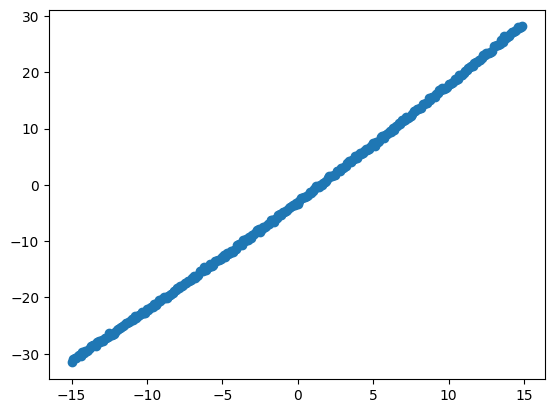

In [40]:
plt.scatter(x[:, 0], y)

Доп.задание. Изобразите поверхность на 3d-графике

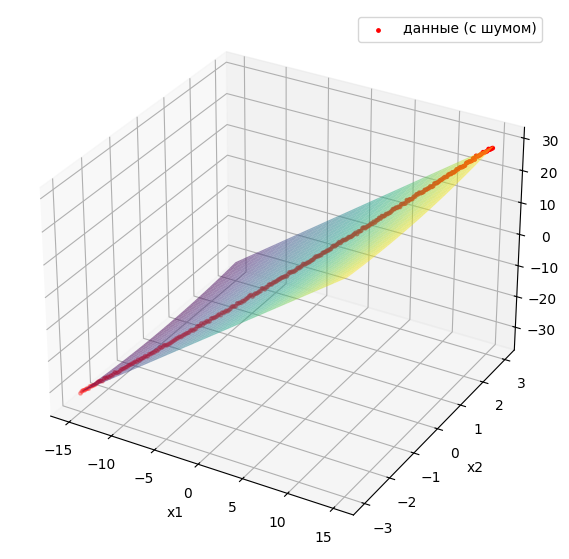

In [41]:
# Поверхность y(x1, x2) = 2*x1 + 0.2*x2^2 - 3 (без шума) и наши точки с шумом
X1, X2 = torch.meshgrid(torch.linspace(-15, 15, 60), torch.linspace(-3, 3, 60), indexing="ij")
Z = 2. * X1 + 0.2 * X2 ** 2 - 3

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X1.numpy(), X2.numpy(), Z.numpy(), cmap="viridis", alpha=0.5)
ax.scatter(x[:, 0].numpy(), x[:, 1].numpy(), y.squeeze().numpy(), c="r", s=6, label="данные (с шумом)")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("y")
ax.legend()
plt.show()


Прежде всего необходимо указать, какие тензоры будут требовать градиенты, с помощью параметра requires_grad. Если requires_grad=False, то это просто массив с числами, посчитать dx/dy не выйдет (по умолчанию).

Если же requires_grad=True, то фреймворк будит учитывать этот тензор при построении графа вычислений производной.
Например, станет возможно посчитать d(sin(log(x**2) - 3x))/dx.


Итак, как PyTorch строит вычислительный граф и вычисляет градиенты? Вершинами графа являются объекты класса torch.autograd.Node, например, AddBackward, MulBackward - это результаты выполнения операций. Ребрами же являются сами тензоры. Соответственно, у каждого тензора,  для которого требуется вычисление градиентов, есть ссылка на функцию .grad_fn, которая градиент создала, и значение самих частных производных (тоже тензор) .grad. Если градиенты неприменимы, то эта функция станет None.



In [42]:
a = torch.rand(5,2, requires_grad=True)
b = torch.rand(2, 1, requires_grad=True)

In [43]:
mult_res = a @ b
res = mult_res.sum()
res

tensor(3.1350, grad_fn=<SumBackward0>)

In [44]:
mult_res

tensor([[0.8992],
        [0.3520],
        [0.7257],
        [0.2542],
        [0.9040]], grad_fn=<MmBackward0>)

In [45]:
mult_res.grad_fn.next_functions

((<AccumulateGrad at 0x289876b32b0>, 0),
 (<AccumulateGrad at 0x289876b2950>, 0))

In [46]:
print(a.grad)

None


А как же получить значения градиентов? Тензоры что-то содержат, операции все известны. На самом деле еще при вычислении значения выражения уже известно, какие операции производятся, поэтому и производную можно посчитать. То, как конкретно это делается, вы узнаете на лекции по backpropagation.

In [47]:
res.backward()

In [48]:
b.grad.data

tensor([[3.1691],
        [2.2959]])

In [49]:
mult_res.grad

C:\Users\Zver\AppData\Local\Temp\ipykernel_25996\6217836.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\build\aten\src\ATen/core/TensorBody.h:494.)
  mult_res.grad


Граф перестраивается на каждом проходе. Это удобно - мы не зависим от размеров семпплов и батчей, но дает оверхед, который может стать значительным у больших моделей. 

Начиная с PyTorch 2.0 появилась возможность получать статические вычислительные графы, что позволяет сильно ускорить обучение, об этом детально мы, возможно, поговорим позже. Пока что просто помните, что если вам необходимо ускорить инференс или обучение модели, один из простейших вариантов - использовать torch.compile и статические графы. В таком случае, многие операции на ускорителе можно оптимизировать, а лишние этапы перестройки опустить.


Перейдем к нашим данным. Попробуем обучить простую линейную модель с помощью градиентного спуска.

In [50]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
y_pred = w @ x.T + b
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

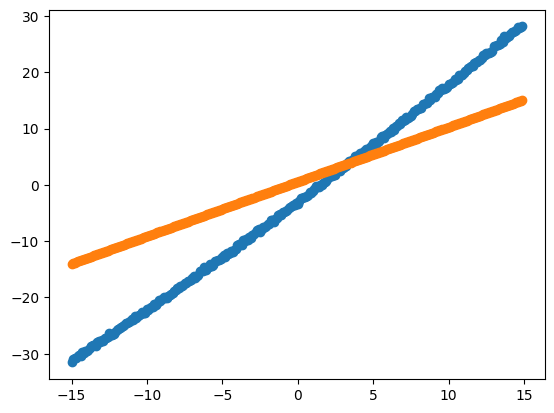

In [51]:
plt.scatter(x[:, 0], y)
plt.scatter(x[:, 0], y_pred.detach().numpy())

Пока не слишком похоже на то, что мы хотим. Для того, чтобы изменения применились, нужно сделать шаг градиентного спуска.

**Задание**. Проведите 100 итераций градиентного спуска для данного набора.
Для этого надо вспомнить, как выглядит этот алгоритм для линейной регрессии

In [52]:
w.grad

tensor([[-154.5874,  -30.9175]])

[0] loss: 111.5996  Weights: tensor([[2.4008, 1.2387]], requires_grad=True)  bias: tensor([0.8783], requires_grad=True)
Gradients: tensor([[-173.2367,  -34.6473]])
Gradients after zero: tensor([[0., 0.]])
[10] loss: 7.8247  Weights: tensor([[1.7804, 1.1146]], requires_grad=True)  bias: tensor([0.2777], requires_grad=True)
Gradients: tensor([[-0.5222, -0.1044]])
Gradients after zero: tensor([[0., 0.]])
[20] loss: 5.3293  Weights: tensor([[1.7782, 1.1142]], requires_grad=True)  bias: tensor([-0.2134], requires_grad=True)
Gradients: tensor([[0.0013, 0.0003]])
Gradients after zero: tensor([[0., 0.]])
[30] loss: 3.6639  Weights: tensor([[1.7779, 1.1141]], requires_grad=True)  bias: tensor([-0.6147], requires_grad=True)
Gradients: tensor([[0.0024, 0.0005]])
Gradients after zero: tensor([[0., 0.]])
[40] loss: 2.5521  Weights: tensor([[1.7777, 1.1141]], requires_grad=True)  bias: tensor([-0.9426], requires_grad=True)
Gradients: tensor([[0.0020, 0.0004]])
Gradients after zero: tensor([[0., 0.]]

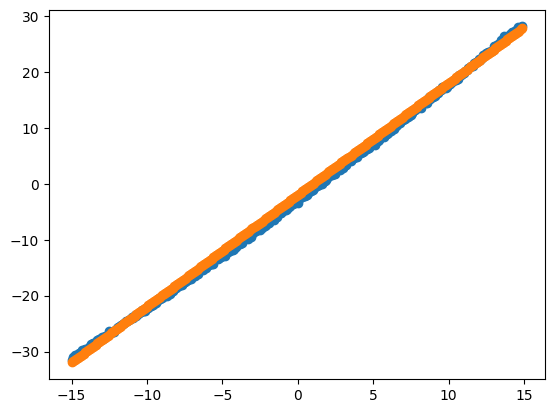

In [ ]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)

# lr подобран из 0.001, 0.005, 0.01, 0.05, 0.1
lr = 0.01

for i in range(100):

    y_pred = w @ x.T + b
    loss = torch.mean((y_pred - y) ** 2)
    loss.backward()
    with torch.no_grad():
        # torch.no_grad() выключает обернутую часть из графа
        # Почему мы не можем сделать так?
        #  w  = w  - 0.1 * w.grad
        #  b  = b  - 0.1 * b.grad
        # Ответ: присваивание создаёт новый тензор, и имя w начинает указывать на него, а не на исходный параметр.
        #  - Внутри no_grad новый тензор имеет requires_grad=False, т.е. перестаёт быть обучаемым:
        #    на следующей итерации w.grad будет None (TypeError: None * float), а градиент по w не считается.
        #  - Вне no_grad это была бы обычная операция графа: w стал бы нелистовым тензором (у него .grad
        #    не заполняется), а граф вычислений рос бы с каждой итерацией.
        # Поэтому параметр нужно менять на месте:

        w -= lr * w.grad
        b -= lr * b.grad

        if i % 10 == 0:
            print(f"[{i}] loss: {loss.item():.4f}  Weights: {w}  bias: {b}")

    if i % 10 == 0:
        print(f"Gradients: {w.grad}")
    # На каждой итерации нужно занулить градиенты
    # иначе они будут копиться и приведут к непредвиденным результатам
    # Это делают через  grad.data.zero_()

    w.grad.data.zero_()
    b.grad.data.zero_()

    if i % 10 == 0:
        print(f"Gradients after zero: {w.grad}")

with torch.no_grad():
    y_pred = w @ x.T + b
print("final loss:", torch.mean((y_pred - y) ** 2).item())
plt.scatter(x[:, 0], y.squeeze())
plt.scatter(x[:, 0], y_pred.detach().squeeze().numpy())
plt.show()

# Пайплайн обучения

Кроме собственно тензоров, функций потерь и градиентов, основные составляющие библиотеки как и всегда - датасеты и модели. При этом торч позволяет довольно свободно составлять и то, и другое из простейших блоков, лишь поддерживая необходимые интерфейсы.

Импортируем torch.nn - тут находятся классы, реализующие слои, лоссы, функции ошибок и тд. 
Для примера я использую стандартный датасет для компьютерного зрения - MNIST - содержащий цифры от 0 до 9 в разном написании. Поэтому импортируются некоторые подмодули torchvision


In [54]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [55]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Pytorch позволяет использовать открытые датасеты с хаба. Они все являются подклассами `torch.utils.data.Dataset` и имплементируют методы, специфичные для этого класса данных. Обычно они используются для прототипирования и бенчмаркинга и могут быть загружены по необходимости. Однако если для задачи необxодимо что-то кроме предполагаемой разработчиками функциональности, нужно либо отнаследовать один из них, либо напрямую `torch.utils.data.Dataset`.

Давайте загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist) - один из таких простых бенчмарк-датасетов для компьютерного зрения. Каждый семпл - это черно-белое изображение размером 28х28 с каким-то предметом одежды и ассоциированным классом. Всего набор содержит 60000 + 10000 изображений и 10 классов.


In [56]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [57]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [58]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.reshape(28, 28), cmap="gray")
    plt.show()

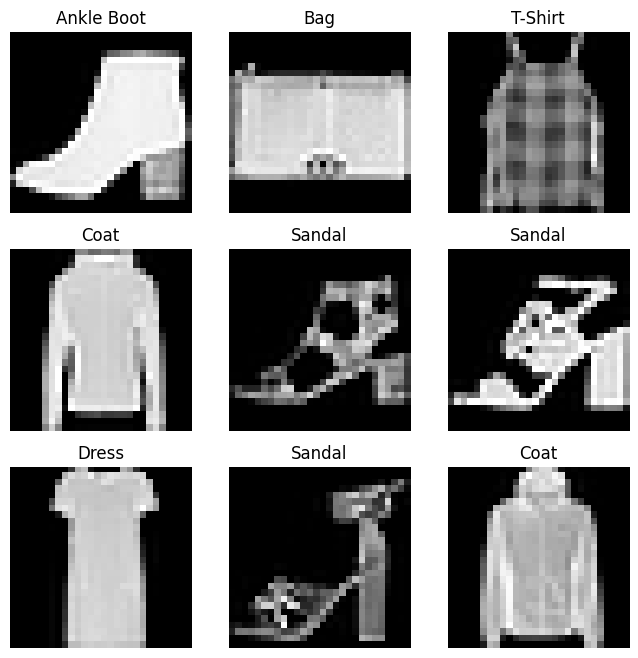

In [59]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Каждый датасет в Pytorch должен наследоваться от класса Dataset и обязательно имплементировать методы `__init__, __len__, __getitem__`. В `__init__` обычно кроме прочего определяются трансформации, которые будут применяться к данным. Это может быть преобразование PIL.Image в тензоры, добавление шума, сдвиги и т.д. 
Pytorch предоставляет большое количество трансформаций, но наиболее популярная и удобная библиотека, реализующая трансформации для изображений - *albumentations*. 

`__len__` - должна возвращать размер датасета (например, чисо строк в файле с аннотациями)

`__getitem__` - должен возвращать семпл данных, например, вектор признаков и y. Однако он может возвращать еще и дополнительную информацию, например, y может состоять из набора bboxoв и  сегментационных масок для детекции, класса изображения итп. Обычно возвращается tuple. В целом, возвращаться может любая структура, которую можно представить как набор тензоров, соответствующих одному семплу и входу модели.
Внутри этого метода может происходить загрузка семпла, его трансформации и другие необходимые манипуляции. Очевидно, что он может возвращать не только изображение, но и любые другие данные, и временные ряды, и табличные данные, и облака точек, и другое. 


Давайте реализуем такой датасет для FashionMNIST. Конечно, можно было бы спокойно использовать встроенный, но так не интересно )

In [60]:
from torchvision.datasets.mnist import read_image_file, read_label_file

In [61]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))

        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.targets[idx]
        
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

Проинициализируйте ваш новый датасет так же, как и ранее встроенный.

In [ ]:
# torchvision при download=True кладёт сырые файлы в data/FashionMNIST/raw
# (ячейка со встроенным FashionMNIST выше должна быть выполнена хотя бы один раз)
DATA_DIR = "data/FashionMNIST/raw"

def to_float_tensor(img):
    """uint8 [28, 28] -> float32 [1, 28, 28] в диапазоне [0, 1]."""
    return img.unsqueeze(0).float() / 255.

train_data = FashionMNISTDataset(DATA_DIR, train=True, transform=to_float_tensor)
test_data = FashionMNISTDataset(DATA_DIR, train=False, transform=to_float_tensor)
len(train_data), len(test_data)

(60000, 10000)

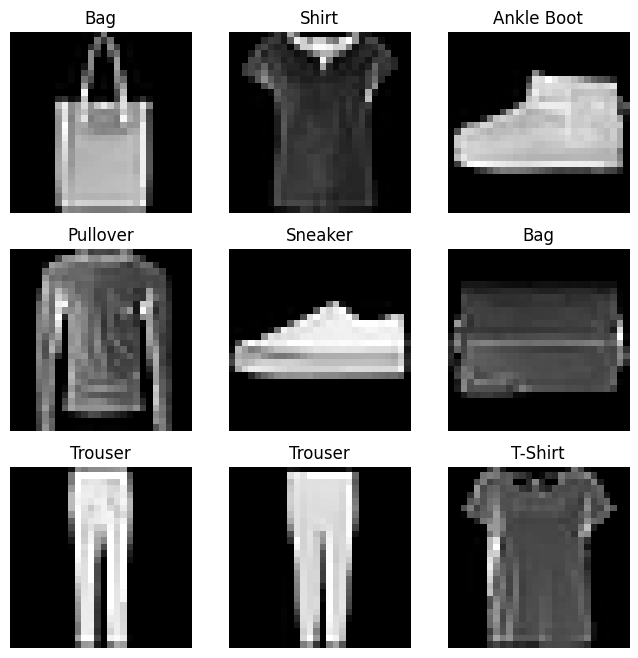

In [63]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Датасет возвращает один семпл за раз, однако часто наши мощности позволяют обрабатывать больше данных. При работе с таблицами модель получает на вход вообще весь набор сразу или достаточно большими порциями. Когда речь заходит о тензорах и наборах с сотнями тысяч и даже миллионами семплов, это невозможно. На помощь приходит батчевая обработка, когда из датасета берутся небольшие порции данных за раз (используя индекс). За соединение семплов во вход модели отвечает класс DataLoader. Каждую эпоху данные шаффлятся, чтобы уменьшить переобучение. 

In [64]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


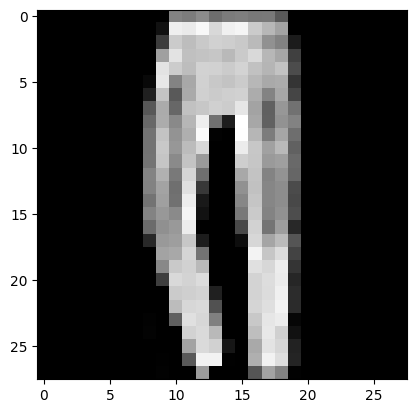

Label: 1


In [65]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Глубокое обучение чаще всего связывают с GPU, и не зря. Имея дело с тензорами и тензорными вычислениями, мы производим огромное количество элементарных операций. Каждое ядро CPU способно произвести только одно вычисление за такт. GPU был создан для обработки графики, где требуется также большое количество простых вычислений, и поэтому может ускорить обработку данных в тысячи раз. Это все должно быть хорошо Вам известно из других курсов)

К сожалению, часто компьютер не поддерживает вычисления на GPU, например, у него просто нет дискретной видеокарты. Pytorch позволяет проводить все операции на CPU, так что его можно использовать где угодно.



In [66]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cuda device


*Дополнительное задание: адаптируйте весь код для `accelerate`. Это очень удобная библиотека для адаптации PyTorch кода для любой распределенной конфигурации. Кроме того, она позволяет упростить работу, даже если нам нужно перенести вычисления на GPU или CPU, автоматизируя этот процесс (иначе нам нужно постоянно вызывать `.to(device)`)*
*Для этого импортируйте нужный Accelerator из accelerate. Далее достаточно вызвать accelerator.prepare(elements)*

**Так как основной код находится далее, решение перенесено в самый конец ноутбука (раздел «Дополнительно: accelerate»).**

Теперь создадим класс модели и интстанциируем её. В данном случае это простой перцептрон с тремя слоями. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.
Каждая модель должна имплементировать два метода - `__init__` и `forward(self, *args, **kwargs)`. В первом обычно задается ее структура и другие параметры. Модель  может даже содержать другие модели!

`forward` получает на вход Х, но он может получать несколько разных входов, маски и тд. Обычно возвращаются либо выходы с последнего слоя (один или несколько). Но, например, стандартные модели детекции возвращают в режиме обучения значение лосса, а непосредственные предсказания только в режиме тестирования.

Вызывая `model(data)`, на самом деле мы вызываем именно метод `forward`

Для того, чтобы понять, как устроен слой в Pytorch, создадим простой слой для превращения изображения в вектор.
Пусть это будет класс MyFlatten. Изображения (и, что более актуально, промежуточные представления или, иными словами, карты, внутри модели) изначально имеют размер N x C x H x W, где:

N - число семплов в батче
C - число каналов на входе в конкретный слой. Если вход с 3 каналами, это 3, но в середине модели это может быть любое число, например, 128.
H - высота карты
W - ширина карты

Когда мы делаем что-то вроде двумерной свертки, это стандартное представление данных, которое позволяет восстановить пространственные зависимости между элементами карты. Однако, когда мы используем полносвязные модели, каждый семпл представлен единым вектором. В простом случае больше не нужно разделять разные каналы, строки и столбцы данных. Таким образом, мы используем операцию "вытянуть в вектор", чтобы превратить значения C x H x W в представление C * H * W. 

**Задание**: допишите класс MyFlatten. Этот слой при вызове должен принимать на вход тензор размера B x C x H x W и возвращать тензор размера B x [C * H * W]. Пример: батч картинок 2 x 3(rgb) x 16(h) x 16(w)] -> 2 x 768

In [67]:
class MyFlatten(nn.Module):
    def forward(self, x):
        # [B, C, H, W] -> [B, C*H*W];
        return x.reshape(x.size(0), -1)

# проверка: [2, 3, 16, 16] -> [2, 768]
MyFlatten()(torch.rand(2, 3, 16, 16)).shape

torch.Size([2, 768])

In [68]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = MyFlatten()
        self.fc = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): MyFlatten()
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Слои: http://pytorch.org/docs/nn.html

Активации: http://pytorch.org/docs/nn.html#non-linear-activations

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [69]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Задание: 
1) Выберите как минимум еще 2 разные функции ошибки из https://pytorch.org/docs/stable/nn.html#loss-functions и обучите модель с ними
2) Выберите как минимум еще 1 оптимизатор из https://pytorch.org/docs/stable/optim.html и обучите каждую из моделей с ним

В результате у вас должна получиться таблица с лучшими значениями лосса для каждого случая для обучения и теста. В идеале оформите их в виде pandas.DataFrame или другой таблицы с удобным выводом.

**Решение - ниже, после обучения базовой модели (раздел «Сравнение функций ошибки и оптимизаторов»).**

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [ ]:
#свой train

def train(dataloader, model, loss_fn, optimizer, scheduler=None, verbose=True):
    """Одна эпоха обучения. Возвращает средний лосс по батчам за эпоху
    (минимум по эпохам отслеживается снаружи - в цикле по эпохам / в fit)."""
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0.0
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:   
            scheduler.step()

        total_loss += loss.item()
        if verbose and batch_idx % 100 == 0:
            current = (batch_idx + 1) * len(inputs)   
            print(f"loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")

    return total_loss / len(dataloader)

In [ ]:
NUM_CLASSES = 10
# свой test

def test(dataloader, model, loss_fn, verbose=True):
    """Валидация/тест. Возвращает dict: loss, accuracy, precision (macro), recall (macro)."""
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            pred_labels = preds.argmax(1)
            num_correct += (pred_labels == targets).type(torch.float).sum().item()
            conf += torch.bincount(targets * NUM_CLASSES + pred_labels,
                                   minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES).cpu()
    test_loss /= num_batches
    correct = num_correct / size

    tp = conf.diag().float()
    precision = (tp / conf.sum(0).clamp(min=1)).mean().item()
    recall = (tp / conf.sum(1).clamp(min=1)).mean().item()

    if verbose:
        print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Precision: {100*precision:>0.1f}%, "
              f"Recall: {100*recall:>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return {"loss": test_loss, "accuracy": correct, "precision": precision, "recall": recall}

Задание: Добавьте метрики precision и recall для проверки

In [72]:
import copy

epochs = 10
best_train_loss, best_test_loss = float("inf"), float("inf")
best_state = None
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    metrics = test(test_dataloader, model, loss_fn)

    # трекинг минимального лосса и лучших весов
    best_train_loss = min(best_train_loss, train_loss)
    if metrics["loss"] < best_test_loss:
        best_test_loss = metrics["loss"]
        best_state = copy.deepcopy(model.state_dict())
print(f"Best train loss: {best_train_loss:.4f}, best test loss: {best_test_loss:.4f}")

Epoch 1
-------------------------------
loss: 2.304285  [   64/60000]
loss: 2.285255  [ 6464/60000]
loss: 2.264801  [12864/60000]
loss: 2.268973  [19264/60000]
loss: 2.255240  [25664/60000]
loss: 2.210005  [32064/60000]
loss: 2.222252  [38464/60000]
loss: 2.182467  [44864/60000]
loss: 2.171642  [51264/60000]
loss: 2.158620  [57664/60000]
Test Error: 
 Accuracy: 24.4%, Precision: 36.1%, Recall: 24.4%, Avg loss: 2.151158 

Epoch 2
-------------------------------
loss: 2.165375  [   64/60000]
loss: 2.103135  [ 6464/60000]
loss: 2.107935  [12864/60000]
loss: 2.113297  [19264/60000]
loss: 2.043064  [25664/60000]
loss: 2.050687  [32064/60000]
loss: 2.036973  [38464/60000]
loss: 1.978108  [44864/60000]
loss: 1.894885  [51264/60000]
loss: 1.832609  [57664/60000]
Test Error: 
 Accuracy: 54.6%, Precision: 54.2%, Recall: 54.6%, Avg loss: 1.888339 

Epoch 3
-------------------------------
loss: 1.890813  [   64/60000]
loss: 1.846819  [ 6464/60000]
loss: 1.837602  [12864/60000]
loss: 1.798358  [192

Осталось сохранить модель для дальнейшего использования. 

In [73]:
torch.save(best_state, "best_model.pth")  # веса эпохи с минимальным test-лоссом

Какая точность получилась? 

**Ответ** ~70.5-71% (может варьироваться в пределах +-1%), test loss ≈ 0.78; precision/recall совпадают с accuracy. Модель недообучена: лосс на 10-й эпохе ещё заметно падает, потому что SGD с lr=1e-3 учится медленно. Её можно сильно улучшить увеличением lr/числа эпох, моментумом или Adam.

## Сравнение функций ошибки и оптимизаторов

Сравниваем 4 функции ошибки (`CrossEntropy`, `MultiMarginLoss`, `BCEWithLogits` на one-hot, `MSE` на softmax и one-hot) и 3 оптимизатора (`SGD`, `Adam`, `RMSprop`). Для каждой пары обучаем новую модель и записываем **минимальный** train-лосс (средний за эпоху) и **минимальный** test-лосс по эпохам. Чтобы эксперимент был честным, добавлена ещё и лучшая test accuracy: значения лосса у разных функций ошибки лежат в разных шкалах и напрямую не сопоставимы - сравнивать их стоит только внутри одной функции ошибки (по оптимизаторам).

In [74]:
import copy
import pandas as pd
import torch.nn.functional as F


class OneHotLoss(nn.Module):
    """Обёртка: превращает метки классов в one-hot, чтобы использовать лоссы,
    которые ждут вектор-таргет (BCE, MSE ...). softmax=True применяет softmax к логитам."""
    def __init__(self, base_loss, num_classes=10, softmax=False):
        super().__init__()
        self.base_loss, self.num_classes, self.softmax = base_loss, num_classes, softmax

    def forward(self, logits, targets):
        onehot = F.one_hot(targets, self.num_classes).float()
        out = logits.softmax(dim=1) if self.softmax else logits
        return self.base_loss(out, onehot)


loss_zoo = {
    "CrossEntropy":  lambda: nn.CrossEntropyLoss(),
    "MultiMargin":   lambda: nn.MultiMarginLoss(),
    "BCEWithLogits": lambda: OneHotLoss(nn.BCEWithLogitsLoss()),
    "MSE (softmax)": lambda: OneHotLoss(nn.MSELoss(), softmax=True),
}
optim_zoo = {
    "SGD":     lambda params: torch.optim.SGD(params, lr=1e-3),
    "Adam":    lambda params: torch.optim.Adam(params, lr=1e-3),
    "RMSprop": lambda params: torch.optim.RMSprop(params, lr=1e-3),
}


def fit(model, loss_fn, optimizer, epochs, train_loader, eval_loader,
        scheduler=None, verbose=True, select_by="loss"):
    """Цикл по эпохам с трекингом минимальных лоссов и лучших весов (по eval-лоссу или accuracy)."""
    history = []
    best = {"train_loss": float("inf"), "eval_loss": float("inf"), "accuracy": 0.0, "state": None}
    for epoch in range(epochs):
        if verbose:
            print(f"Epoch {epoch+1}\n-------------------------------")
        train_loss = train(train_loader, model, loss_fn, optimizer, scheduler=scheduler, verbose=verbose)
        m = test(eval_loader, model, loss_fn, verbose=verbose)
        history.append({"epoch": epoch + 1, "train_loss": train_loss, **m})

        improved = m["loss"] < best["eval_loss"] if select_by == "loss" else m["accuracy"] > best["accuracy"]
        if improved:
            best["state"] = copy.deepcopy(model.state_dict())
        best["train_loss"] = min(best["train_loss"], train_loss)
        best["eval_loss"] = min(best["eval_loss"], m["loss"])
        best["accuracy"] = max(best["accuracy"], m["accuracy"])
    return history, best


def run_experiment(loss_name, opt_name, epochs=5, seed=0):
    torch.manual_seed(seed)
    model_ = NeuralNetwork().to(device)
    loss_fn_ = loss_zoo[loss_name]()
    optimizer_ = optim_zoo[opt_name](model_.parameters())
    _, best = fit(model_, loss_fn_, optimizer_, epochs, train_dataloader, test_dataloader, verbose=False)
    return {"loss": loss_name, "optimizer": opt_name,
            "best_train_loss": best["train_loss"], "best_test_loss": best["eval_loss"],
            "best_test_acc": best["accuracy"]}


EPOCHS_GRID = 5   # можно увеличить до 10 для более точного сравнения (дольше считается)
results = []
for l_name in loss_zoo:
    for o_name in optim_zoo:
        print(f"running: {l_name} + {o_name}")
        results.append(run_experiment(l_name, o_name, EPOCHS_GRID))

df = pd.DataFrame(results)
display(df.round(4))
display(df.pivot(index="loss", columns="optimizer", values="best_test_acc").round(4))

running: CrossEntropy + SGD
running: CrossEntropy + Adam
running: CrossEntropy + RMSprop
running: MultiMargin + SGD
running: MultiMargin + Adam
running: MultiMargin + RMSprop
running: BCEWithLogits + SGD
running: BCEWithLogits + Adam
running: BCEWithLogits + RMSprop
running: MSE (softmax) + SGD
running: MSE (softmax) + Adam
running: MSE (softmax) + RMSprop


,loss,optimizer,best_train_loss,best_test_loss,best_test_acc
0,CrossEntropy,SGD,1.1470,1.0754,0.6488
1,CrossEntropy,Adam,0.2773,0.3630,0.8642
2,CrossEntropy,RMSprop,0.2802,0.3487,0.8742
3,MultiMargin,SGD,0.2265,0.2134,0.6522
4,MultiMargin,Adam,0.0352,0.0460,0.8754
5,MultiMargin,RMSprop,0.0355,0.0463,0.8728
6,BCEWithLogits,SGD,0.3468,0.3449,0.1464
7,BCEWithLogits,Adam,0.0509,0.0649,0.8685
8,BCEWithLogits,RMSprop,0.0507,0.0615,0.8741
9,MSE (softmax),SGD,0.0899,0.0898,0.1157


optimizer,Adam,RMSprop,SGD
loss,,,
BCEWithLogits,0.8685,0.8741,0.1464
CrossEntropy,0.8642,0.8742,0.6488
MSE (softmax),0.8743,0.8744,0.1157
MultiMargin,0.8754,0.8728,0.6522


**Выводы по таблице:**
- Adam и RMSprop (lr=1e-3) дают ≈86.5–87.5% accuracy при любой функции ошибки; различия между лоссами здесь в пределах шума (1 seed, 5 эпох).
- SGD с lr=1e-3 слишком медленный: модель недообучена, результат падает (особенно сильно с MSE и BCE)

Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы и мою модель без слоя MyFlatten(). Запустите обучение заново. Какая точность получилась теперь?

In [75]:
class FashionMNISTVectorDataset(FashionMNISTDataset):
    """То же, что FashionMNISTDataset, но возвращает вектор длины 784 вместо матрицы [1, 28, 28]."""
    def __getitem__(self, idx):
        image, label = super().__getitem__(idx)   # применяет transform (-> [1, 28, 28])
        return image.reshape(-1), label           # -> [784]


class NeuralNetworkNoFlatten(nn.Module):
    """Та же сеть, но без слоя MyFlatten: вход уже вектор [B, 784]."""
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.fc(x)


train_vec = FashionMNISTVectorDataset(DATA_DIR, train=True, transform=to_float_tensor)
test_vec = FashionMNISTVectorDataset(DATA_DIR, train=False, transform=to_float_tensor)
train_vec_loader = DataLoader(train_vec, batch_size=64, shuffle=True)
test_vec_loader = DataLoader(test_vec, batch_size=64, shuffle=False)
print(train_vec[0][0].shape)   # torch.Size([784])

# те же условия, что и в базовом эксперименте: CrossEntropy + SGD(lr=1e-3), 10 эпох
torch.manual_seed(0)
model_vec = NeuralNetworkNoFlatten().to(device)
history_vec, best_vec = fit(model_vec, nn.CrossEntropyLoss(),
                            torch.optim.SGD(model_vec.parameters(), lr=1e-3),
                            epochs=10, train_loader=train_vec_loader, eval_loader=test_vec_loader,
                            verbose=False)
print(f"best test acc: {best_vec['accuracy']:.4f}, best test loss: {best_vec['eval_loss']:.4f}")

torch.Size([784])
best test acc: 0.7110, best test loss: 0.7788


**Ответ на вопрос «Какая точность получилась теперь?»** Лучшая test accuracy - ~71.1 % (против ~70.5-71% с MyFlatten) за 10 эпох: CrossEntropy, SGD с lr=1e-3, batch 64. `MyFlatten` не имеет параметров и лишь переставляет размерности `[B, 1, 28, 28] -> [B, 784]`, а здесь то же самое делается в датасете (`image.reshape(-1)`). Если результат базовой модели отличается на десятые доли процента, это объясняется случайностью (инициализация весов и порядок батчей), а не архитектурой, так как это по сути та же модель.

Задание: придумайте свою собственную модель. Улучшите результат (но без сверток)

При подборе гиперпараметров (это те параметры, которые не обучаются, например, lr) и обучении модели помните:
1. Если параметры выбраны хорошо, улучшение видно уже после нескольких сотен итераций.
2. Настраивайте гиперпараметры от грубых значений к точным: начните с тестирования большого диапазона гиперпараметров всего за несколько итераций обучения, чтобы найти комбинации параметров, которые вообще работают.
3. После того, как вы нашли несколько наборов параметров, которые, по-видимому, работают, выполните более тщательный поиск по этим параметрам. Возможно, вам придется тренировать модель большее число эпох.
4. Нужно использовать валидационный набор для поиска. Этот набор нужно выделить из тренировочного и вызывать на нем функцию test.

In [76]:
from torch.utils.data import random_split

# --- данные: нормализация + вектор + валидационная выборка из train (по совету выше) ---
MEAN, STD = 0.2860, 0.3530   # среднее/std пикселей FashionMNIST

def to_norm_vector(img):
    """uint8 [28, 28] -> нормализованный float32 вектор [784]"""
    return (((img.float() / 255.) - MEAN) / STD).reshape(-1)

full_train = FashionMNISTDataset(DATA_DIR, train=True, transform=to_norm_vector)
test_set = FashionMNISTDataset(DATA_DIR, train=False, transform=to_norm_vector)
train_set, val_set = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(42))

train_loader2 = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=512, shuffle=False)
test_loader2 = DataLoader(test_set, batch_size=512, shuffle=False)


# --- модель: глубже и шире + BatchNorm + Dropout, без свёрток ---
class BetterMLP(nn.Module):
    def __init__(self, in_dim=784, hidden=(1024, 512, 256), p=0.3, n_classes=10):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# --- грубый поиск гиперпараметров на валидации (3 эпохи на конфиг) ---
search_results = []
for lr in [1e-2, 3e-3, 1e-3]:
    for p in [0.1, 0.3]:
        torch.manual_seed(0)
        m_ = BetterMLP(p=p).to(device)
        opt_ = torch.optim.AdamW(m_.parameters(), lr=lr, weight_decay=1e-4)
        _, best = fit(m_, nn.CrossEntropyLoss(), opt_, epochs=3, train_loader=train_loader2,
                      eval_loader=val_loader, verbose=False, select_by="accuracy")
        search_results.append({"lr": lr, "dropout": p, "val_acc": best["accuracy"], "val_loss": best["eval_loss"]})
search_df = pd.DataFrame(search_results).sort_values("val_acc", ascending=False)
display(search_df.round(4))

# --- финальное обучение лучшей конфигурации: больше эпох + OneCycleLR ---
best_cfg = search_df.iloc[0]
EPOCHS = 20
torch.manual_seed(0)
model_final = BetterMLP(p=float(best_cfg["dropout"])).to(device)
opt_final = torch.optim.AdamW(model_final.parameters(), lr=float(best_cfg["lr"]), weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt_final, max_lr=float(best_cfg["lr"]),
                                            total_steps=EPOCHS * len(train_loader2))
history_final, best_final = fit(model_final, nn.CrossEntropyLoss(), opt_final, EPOCHS,
                                train_loader2, val_loader, scheduler=sched,
                                verbose=False, select_by="accuracy")

# лучшие по валидации веса оцениваем на тесте ОДИН раз
model_final.load_state_dict(best_final["state"])
print(f"best val acc: {best_final['accuracy']:.4f}")
final_metrics = test(test_loader2, model_final, nn.CrossEntropyLoss())

,lr,dropout,val_acc,val_loss
2,0.003,0.1,0.8774,0.3334
3,0.003,0.3,0.8734,0.3383
4,0.001,0.1,0.8712,0.3402
5,0.001,0.3,0.8712,0.3476
0,0.010,0.1,0.8666,0.3581
1,0.010,0.3,0.8620,0.3635


best val acc: 0.9036
Test Error: 
 Accuracy: 90.6%, Precision: 90.6%, Recall: 90.6%, Avg loss: 0.342817 



Таблица отсортирована по убыванию val_acc

Что улучшено относительно базовой модели (всё без свёрток):
1. Нормализация входа (вычитание среднего и деление на std) - градиентам проще, оптимизация быстрее.
2. Архитектура: 3 скрытых слоя 1024-512-256, BatchNorm после каждого линейного слоя (стабилизирует обучение, позволяет большой lr) и Dropout (регуляризация против переобучения).
3. Оптимизатор AdamW (адаптивный шаг + weight decay) вместо SGD с lr=1e-3.
4. Расписание lr OneCycleLR и больше эпох (20 вместо 10).
5. Подбор гиперпараметров (lr, dropout) от грубого к точному на отдельной валидационной выборке из train (55000/5000); тест использован только один раз в конце.

Результат: ~90.6% на тесте (против ~70.5-71% на основной модели)

## Дополнительно: accelerate

Адаптация цикла обучения под `accelerate`: `accelerator.prepare(...)` сам переносит модель и батчи на нужное устройство (поэтому не нужны `.to(device)`), `loss.backward()` заменяется на `accelerator.backward(loss)`, а метрики при распределённом запуске собираются через `gather_for_metrics`.

In [77]:
#%pip install accelerate
from accelerate import Accelerator


def train_acc(dataloader, model, loss_fn, optimizer, accelerator):
    model.train()
    total_loss = 0.0
    for inputs, targets in dataloader:        # .to(device) не нужен - батчи уже на нужном устройстве
        preds = model(inputs)
        loss = loss_fn(preds, targets)
        optimizer.zero_grad()
        accelerator.backward(loss)            # вместо loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)


def test_acc(dataloader, model, loss_fn, accelerator):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            preds = model(inputs)
            total_loss += loss_fn(preds, targets).item()
            # собираем предсказания со всех процессов (и отбрасываем дубликаты в конце эпохи)
            p_all, t_all = accelerator.gather_for_metrics((preds.argmax(1), targets))
            correct += (p_all == t_all).sum().item()
            n += len(t_all)
    return total_loss / len(dataloader), correct / n


accelerator = Accelerator()
torch.manual_seed(0)
acc_model = NeuralNetwork()                    # без .to(device)
acc_loss_fn = nn.CrossEntropyLoss()
acc_optimizer = torch.optim.SGD(acc_model.parameters(), lr=1e-3)
acc_train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
acc_test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

acc_model, acc_optimizer, acc_train_loader, acc_test_loader = accelerator.prepare(
    acc_model, acc_optimizer, acc_train_loader, acc_test_loader)

for epoch in range(10):
    tr_loss = train_acc(acc_train_loader, acc_model, acc_loss_fn, acc_optimizer, accelerator)
    te_loss, te_acc = test_acc(acc_test_loader, acc_model, acc_loss_fn, accelerator)
    accelerator.print(f"epoch {epoch+1}: train loss {tr_loss:.4f}, test loss {te_loss:.4f}, test acc {te_acc:.4f}")

epoch 1: train loss 2.2387, test loss 2.1627, test acc 0.5029
epoch 2: train loss 2.0442, test loss 1.8996, test acc 0.6013
epoch 3: train loss 1.7077, test loss 1.5248, test acc 0.6174
epoch 4: train loss 1.3692, test loss 1.2471, test acc 0.6363
epoch 5: train loss 1.1472, test loss 1.0766, test acc 0.6489
epoch 6: train loss 1.0088, test loss 0.9690, test acc 0.6569
epoch 7: train loss 0.9194, test loss 0.8972, test acc 0.6727
epoch 8: train loss 0.8578, test loss 0.8468, test acc 0.6841
epoch 9: train loss 0.8129, test loss 0.8087, test acc 0.6968
epoch 10: train loss 0.7784, test loss 0.7788, test acc 0.7110


In [78]:
def test_acc_full(dataloader, model, loss_fn, accelerator, verbose=True):
    """Как test(), но для accelerate: loss, accuracy, precision (macro), recall (macro)."""
    model.eval()
    total_loss = 0.0
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)  # строки - истинный класс, столбцы - предсказанный
    with torch.no_grad():
        for inputs, targets in dataloader:
            preds = model(inputs)
            total_loss += loss_fn(preds, targets).item()
            # собираем предсказания со всех процессов (и отбрасываем дубликаты в конце эпохи)
            p_all, t_all = accelerator.gather_for_metrics((preds.argmax(1), targets))
            conf += torch.bincount(t_all * NUM_CLASSES + p_all,
                                   minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES).cpu()

    test_loss = total_loss / len(dataloader)
    correct = conf.diag().sum().item() / conf.sum().item()
    tp = conf.diag().float()
    precision = (tp / conf.sum(0).clamp(min=1)).mean().item()
    recall = (tp / conf.sum(1).clamp(min=1)).mean().item()

    if verbose:
        accelerator.print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Precision: {100*precision:>0.1f}%, "
                          f"Recall: {100*recall:>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return {"loss": test_loss, "accuracy": correct, "precision": precision, "recall": recall}


# итоговая проверка на тесте после обучения
final_metrics_acc = test_acc_full(acc_test_loader, acc_model, acc_loss_fn, accelerator)

Test Error: 
 Accuracy: 71.1%, Precision: 71.5%, Recall: 71.1%, Avg loss: 0.778811 



Результат на 10 эпохах примерно такой же - ~71%